# 08 – Đặc trưng quá khứ gần (RQ4)

**RQ4:** Thêm thông tin tiêu thụ 10–60 phút trước cải thiện dự đoán bao nhiêu?

Notebook 07 cho thấy cảm biến môi trường + thời tiết + giờ chỉ giải thích ~16% phương sai. Phần lớn biến động là do
**con người bật/tắt thiết bị** – không quan sát được trực tiếp. Nhưng hành vi này có **quán tính**: máy giặt, lò nướng
đang chạy lúc 18:00 thì nhiều khả năng vẫn chạy lúc 18:10. Giá trị tiêu thụ ngay trước đó là cách gián tiếp để "nhìn" hành vi.

**Bối cảnh sử dụng:** dự báo **10 phút tới** khi đồng hồ điện đã đo được tiêu thụ đến hiện tại (bài toán *nowcasting*,
phổ biến trong quản lý phụ tải). Đây là bài toán khác với notebook 04–07 (chỉ dùng môi trường), nên nhóm báo cáo
**cả hai** thiết lập.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso
from sklearn.neural_network import MLPRegressor

from src.config import RANDOM_STATE, TABLES_DIR, TARGET
from src.data_loader import load_raw_data
from src.evaluate import HourMeanBaseline, regression_metrics
from src.features import LAG_FEATURES, add_lag_features, add_time_features, get_feature_columns, make_xy
from src.preprocessing import make_pipeline
from src.split import time_split
from src.train import cv_evaluate, fit_and_validate
from src.visualization import save_fig, set_style

warnings.filterwarnings("ignore", category=ConvergenceWarning)
set_style()
pd.set_option("display.width", 160)

# Thêm lag trên TOÀN chuỗi rồi mới chia → đầu tập val/test dùng giá trị cuối tập trước (quá khứ thật).
data = add_lag_features(add_time_features(load_raw_data()))
train, val, test = time_split(data)
print("Đặc trưng mới:", LAG_FEATURES)

Đặc trưng mới: ['lag_10m', 'lag_20m', 'lag_30m', 'lag_60m', 'roll_mean_30m', 'roll_mean_60m', 'diff_10m']


## 1. Kiểm tra đặc trưng lag – không rò rỉ
Mỗi đặc trưng tại thời điểm *t* chỉ được dùng giá trị từ *t − 10 phút* trở về trước.

In [2]:
y = data[TARGET]
checks = {
    "lag_10m(t) == y(t-1)": np.allclose(data["lag_10m"][1:], y.shift(1)[1:]),
    "lag_60m(t) == y(t-6)": np.allclose(data["lag_60m"][6:], y.shift(6)[6:]),
    "roll_mean_30m(t) == mean(y(t-3..t-1))": np.allclose(
        data["roll_mean_30m"][3:], (y.shift(1) + y.shift(2) + y.shift(3))[3:] / 3),
    "không đặc trưng nào bằng y(t) ở mọi dòng": not any((data[c] == y).all() for c in LAG_FEATURES),
    "số dòng NaN (chỉ ở đầu chuỗi)": int(data[LAG_FEATURES].isna().any(axis=1).sum()),
}
for k, v in checks.items():
    print(f"{k:<45} {v}")
data[["date", TARGET, *LAG_FEATURES]].iloc[5:11]

lag_10m(t) == y(t-1)                          True
lag_60m(t) == y(t-6)                          True
roll_mean_30m(t) == mean(y(t-3..t-1))         True
không đặc trưng nào bằng y(t) ở mọi dòng      True
số dòng NaN (chỉ ở đầu chuỗi)                 6


,date,Appliances,lag_10m,lag_20m,lag_30m,lag_60m,roll_mean_30m,roll_mean_60m,diff_10m
5,2016-01-11 17:50:00,50,60.0,50.0,50.0,NaN,53.333333,NaN,10.0
6,2016-01-11 18:00:00,60,50.0,60.0,50.0,60.0,53.333333,55.000000,-10.0
7,2016-01-11 18:10:00,60,60.0,50.0,60.0,60.0,56.666667,55.000000,10.0
8,2016-01-11 18:20:00,60,60.0,60.0,50.0,50.0,56.666667,55.000000,0.0
9,2016-01-11 18:30:00,70,60.0,60.0,60.0,50.0,60.000000,56.666667,0.0
10,2016-01-11 18:40:00,230,70.0,60.0,60.0,60.0,63.333333,60.000000,10.0


In [3]:
corr = data[[TARGET, *LAG_FEATURES]].corr()[TARGET].drop(TARGET).sort_values(ascending=False)
print("Tương quan với Appliances(t):")
print(corr.round(3).to_string())
print("\nĐể so sánh – tương quan cao nhất của một cảm biến môi trường:",
      round(data[get_feature_columns("full")].corrwith(data[TARGET]).abs().max(), 3))

Tương quan với Appliances(t):
lag_10m          0.753
roll_mean_30m    0.648
roll_mean_60m    0.587
lag_20m          0.534
lag_30m          0.438
lag_60m          0.324
diff_10m         0.312

Để so sánh – tương quan cao nhất của một cảm biến môi trường: 0.26


## 2. Baseline "giữ nguyên" (persistence)

Khi đã có giá trị quá khứ, baseline đúng phải là **"10 phút tới bằng 10 phút trước"** – mô hình nào dùng lag mà không
vượt được mốc này thì vô ích.

In [4]:
X_tr, y_tr = make_xy(train, "full_lag")
X_va, y_va = make_xy(val, "full_lag")
X_tr0, y_tr0 = make_xy(train, "full")
X_va0, y_va0 = make_xy(val, "full")
cols = list(X_tr.columns)
cols0 = list(X_tr0.columns)
print("Train:", X_tr.shape, "| Validation:", X_va.shape, "| (6 dòng đầu train bị bỏ vì chưa có lag)")

baselines = {
    "Baseline theo giờ": HourMeanBaseline().fit(X_tr, y_tr).predict(X_va),
    "Persistence (= lag_10m)": X_va["lag_10m"].to_numpy(),
    "Trung bình 30 phút trước": X_va["roll_mean_30m"].to_numpy(),
}
pd.DataFrame({k: regression_metrics(y_va, p) for k, p in baselines.items()}).T.round(3)

Train: (13808, 38) | Validation: (2960, 38) | (6 dòng đầu train bị bỏ vì chưa có lag)


,MAE,RMSE,R2,MAPE_%
Baseline theo giờ,48.549,87.200,0.106,54.438
Persistence (= lag_10m),26.162,66.430,0.481,22.714
Trung bình 30 phút trước,32.520,76.869,0.305,28.400


**Nhận xét:**
- Chỉ cần đoán "10 phút tới bằng 10 phút trước" đã được RMSE **66,4 Wh**, R² **0,48**, tốt hơn rất nhiều so với **mọi** mô hình ở notebook 07 (tốt nhất 84,4 Wh, R² 0,16). Tiêu thụ điện có **quán tính** rất mạnh: tương quan giữa `Appliances(t)` và `lag_10m` là 0,75, trong khi cảm biến môi trường tương quan cao nhất chỉ ≈ 0,2.
- Trung bình 30 phút trước kém hơn persistence (76,9 Wh) vì làm mượt nên phản ứng chậm với các đỉnh.
- **Từ đây, mốc phải vượt là persistence 66,4 Wh**, không phải baseline theo giờ.

## 3. Cùng mô hình – có và không có lag

Giữ nguyên siêu tham số tốt nhất từ notebook 04, 05, 07 để so sánh công bằng (chỉ thay bộ đặc trưng).

In [5]:
import json

best_hgb = json.loads((TABLES_DIR / "07_best_hgb_params.json").read_text())
print("HGB dùng siêu tham số từ notebook 07:", best_hgb)


def build_models(feature_cols):
    return {
        "Lasso (alpha=1)": make_pipeline(Lasso(alpha=1.0, max_iter=10000), feature_cols, "linear"),
        "Random Forest (leaf=50)": make_pipeline(
            RandomForestRegressor(n_estimators=100, min_samples_leaf=50, max_features=0.33,
                                  random_state=RANDOM_STATE, n_jobs=-1), feature_cols, "tree"),
        "HGB tinh chỉnh": make_pipeline(
            HistGradientBoostingRegressor(max_iter=300, l2_regularization=1.0, early_stopping=False,
                                          random_state=RANDOM_STATE, **best_hgb), feature_cols, "tree"),
        "MLP (16)": make_pipeline(MLPRegressor(hidden_layer_sizes=(16,), alpha=10.0, max_iter=200,
                                               random_state=RANDOM_STATE), feature_cols, "linear"),
    }


rows = {}
for setting, (Xa, ya, Xb, yb, fc) in {"không lag": (X_tr0, y_tr0, X_va0, y_va0, cols0),
                                      "có lag": (X_tr, y_tr, X_va, y_va, cols)}.items():
    for name, model in build_models(fc).items():
        _, r = fit_and_validate(model, Xa, ya, Xb, yb)
        r.update(cv_evaluate(model, Xa, ya))
        rows[(name, setting)] = r
lag_cmp = pd.DataFrame(rows).T[["train_RMSE", "cv_RMSE", "cv_RMSE_std", "val_RMSE", "val_MAE", "val_R2"]].round(3)
lag_cmp

HGB dùng siêu tham số từ notebook 07: {'learning_rate': 0.02, 'max_leaf_nodes': 7, 'min_samples_leaf': 100}


,,train_RMSE,cv_RMSE,cv_RMSE_std,val_RMSE,val_MAE,val_R2
Lasso (alpha=1),không lag,99.200,96.115,4.960,85.263,49.125,0.146
Random Forest (leaf=50),không lag,86.883,94.031,4.706,84.680,46.652,0.157
HGB tinh chỉnh,không lag,84.235,94.401,4.517,84.391,45.271,0.163
MLP (16),không lag,94.715,96.962,2.973,89.358,49.914,0.061
Lasso (alpha=1),có lag,69.603,67.290,1.831,60.043,26.799,0.576
Random Forest (leaf=50),có lag,67.431,65.661,2.208,57.745,25.858,0.608
HGB tinh chỉnh,có lag,62.802,65.623,2.482,57.355,26.174,0.613
MLP (16),có lag,68.751,70.366,3.023,59.434,27.723,0.585


In [6]:
pivot = lag_cmp["val_RMSE"].unstack()[["không lag", "có lag"]]
pivot["giảm (Wh)"] = pivot["không lag"] - pivot["có lag"]
pivot["giảm (%)"] = 100 * pivot["giảm (Wh)"] / pivot["không lag"]
persist_rmse = regression_metrics(y_va, X_va["lag_10m"])["RMSE"]
pivot["hơn persistence (%)"] = 100 * (persist_rmse - pivot["có lag"]) / persist_rmse
pivot.round(2)

,không lag,có lag,giảm (Wh),giảm (%),hơn persistence (%)
HGB tinh chỉnh,84.39,57.36,27.04,32.04,13.66
Lasso (alpha=1),85.26,60.04,25.22,29.58,9.61
MLP (16),89.36,59.43,29.92,33.49,10.53
Random Forest (leaf=50),84.68,57.74,26.94,31.81,13.07


Đã lưu hình: reports/figures/08_lag_gain.png


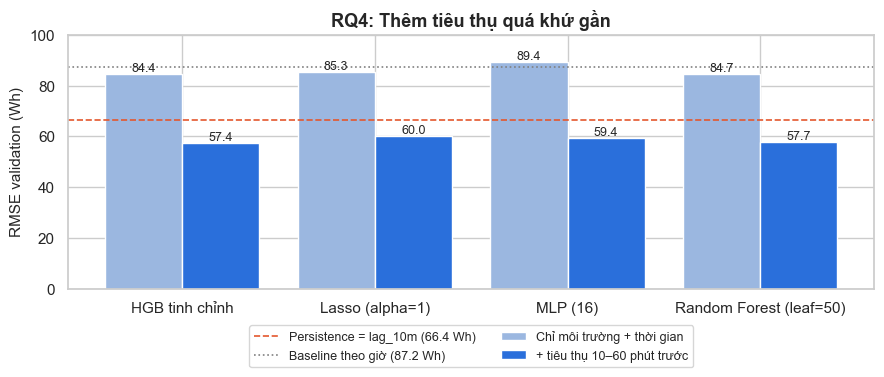

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(pivot))
ax.bar(x - 0.2, pivot["không lag"], width=0.4, label="Chỉ môi trường + thời gian", color="#9bb7e0")
ax.bar(x + 0.2, pivot["có lag"], width=0.4, label="+ tiêu thụ 10–60 phút trước", color="#2a6fdb")
ax.axhline(persist_rmse, color="#e4572e", linestyle="--", linewidth=1.2,
           label=f"Persistence = lag_10m ({persist_rmse:.1f} Wh)")
hour_rmse = regression_metrics(y_va, baselines["Baseline theo giờ"])["RMSE"]
ax.axhline(hour_rmse, color="grey", linestyle=":", linewidth=1.2, label=f"Baseline theo giờ ({hour_rmse:.1f} Wh)")
for i, (a, b) in enumerate(zip(pivot["không lag"], pivot["có lag"])):
    ax.text(i - 0.2, a + 1, f"{a:.1f}", ha="center", fontsize=9)
    ax.text(i + 0.2, b + 1, f"{b:.1f}", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(pivot.index)
ax.set_ylabel("RMSE validation (Wh)")
ax.set_ylim(0, 100)
ax.set_title("RQ4: Thêm tiêu thụ quá khứ gần")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=9)
fig.tight_layout()
save_fig(fig, "08_lag_gain")
plt.show()

**Nhận xét:**
- Thêm 7 đặc trưng quá khứ gần làm RMSE validation của **mọi** mô hình giảm khoảng **30%** (≈ 84–89 → 57–60 Wh), R² tăng từ ≈ 0,16 lên ≈ **0,61**.
- Mô hình tốt nhất (HGB, 57,4 Wh) **hơn persistence 13,6%**. Mô hình học máy vẫn có giá trị: nó học được khi nào đỉnh tiêu thụ sắp kết thúc hay tiếp tục, thay vì chỉ lặp lại giá trị cũ.
- Thứ hạng các mô hình gần như không đổi: HGB ≈ Random Forest (chênh 0,4 Wh) > MLP ≈ Lasso. Chênh lệch giữa HGB và RF nhỏ hơn độ lệch chuẩn CV (~2,3 Wh) → **không phân biệt được**.
- Độ lệch chuẩn CV cũng giảm một nửa (≈ 4,6 → ≈ 2,3 Wh): mô hình ổn định hơn giữa các giai đoạn thời gian.

## 4. Cảm biến môi trường còn đóng góp gì khi đã có lag?

So sánh HGB với 3 bộ đặc trưng: chỉ lag + thời gian / lag + thời gian + `lights` / đầy đủ.

In [8]:
lag_time = get_feature_columns("lag_time", include_control=False)
ablation_sets = {
    "lag + thời gian (lag_time)": lag_time,
    "lag + thời gian + lights": lag_time + ["lights"],
    "đầy đủ (full_lag)": cols,
}
abl = {}
for name, fc in ablation_sets.items():
    model = build_models(fc)["HGB tinh chỉnh"]
    _, r = fit_and_validate(model, X_tr[fc], y_tr, X_va[fc], y_va)
    r.update(cv_evaluate(model, X_tr[fc], y_tr))
    abl[name] = r | {"số đặc trưng": len(fc)}
ablation = pd.DataFrame(abl).T
ablation.to_csv(TABLES_DIR / "08_ablation.csv")
ablation[["số đặc trưng", "cv_RMSE", "cv_RMSE_std", "val_RMSE", "val_MAE", "val_R2"]].round(3)

,số đặc trưng,cv_RMSE,cv_RMSE_std,val_RMSE,val_MAE,val_R2
lag + thời gian (lag_time),12.0,65.155,2.571,56.901,25.031,0.619
lag + thời gian + lights,13.0,65.372,2.562,56.838,24.744,0.620
đầy đủ (full_lag),38.0,65.623,2.482,57.355,26.174,0.613


In [9]:
lag_cmp.to_csv(TABLES_DIR / "08_lag_comparison.csv")
print("Đã lưu reports/tables/08_lag_comparison.csv và 08_ablation.csv")

Đã lưu reports/tables/08_lag_comparison.csv và 08_ablation.csv


**Nhận xét:**
- Khi đã có lag, bỏ toàn bộ 25 biến cảm biến + thời tiết + `rv1` **không làm mô hình tệ đi** (validation 57,0 Wh với 12 đặc trưng so với 57,4 Wh với 38 đặc trưng; CV cũng tốt nhất ở bộ 12 đặc trưng). Thông tin hữu ích của cảm biến (ví dụ nhiệt độ/độ ẩm bếp tăng khi nấu ăn) **đã nằm sẵn** trong số đo điện ngay trước đó.

### Kết luận RQ4

| Thiết lập | Mô hình tốt nhất | Validation RMSE | R² |
|---|---|---|---|
| Chỉ môi trường + thời gian (`full`) | HGB | 84,4 Wh | 0,16 |
| Persistence (không học) | – | 66,4 Wh | 0,48 |
| + tiêu thụ 10–60 phút trước (`full_lag`) | HGB | 57,4 Wh | 0,61 |
| Chỉ thời gian + quá khứ gần (`lag_time`, 12 đặc trưng) | HGB | 57,0 Wh | 0,62 |

- Thông tin quá khứ gần **cải thiện RMSE khoảng 32%** và là yếu tố quyết định, lớn hơn rất nhiều so với việc chọn mô hình (RQ2: chỉ chênh ~1 Wh).
- **Ý nghĩa thực tế:** nếu nhà có đồng hồ điện thông minh, mô hình dự báo 10 phút tới chỉ cần thời gian + lịch sử tiêu thụ. Cảm biến môi trường chỉ có ích khi **không có** lịch sử tiêu thụ (thiết lập của bài báo gốc).
- **Hạn chế:** chỉ dự báo được **một bước** (10 phút). Dự báo xa hơn (1 giờ, 1 ngày) sẽ khó hơn nhiều vì quán tính giảm nhanh (tương quan với `lag_60m` chỉ còn 0,32).

→ Notebook 09 chốt hai mô hình (một cho mỗi thiết lập), đánh giá **một lần** trên tập test và trả lời RQ3.